<a href="https://colab.research.google.com/github/ChibogwuAdaezeEdozie/Calibration-and-abstention-for-chest-X-ray-pneumonia-classification/blob/main/Chest_Xray.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import hashlib
import re
import random
from PIL import Image

import kagglehub
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import GroupShuffleSplit

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

In [3]:
# Download latest version
path = kagglehub.dataset_download("tolgadincer/labeled-chest-xray-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'labeled-chest-xray-images' dataset.
Path to dataset files: /kaggle/input/labeled-chest-xray-images


In [4]:
DATA_DIR = os.path.join(path, "chest_xray")
EPOCHS = 5
BATCH_SIZE = 32
SEED = 42
PRETRAINED = True

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [5]:
# load file paths and labels
def list_images(folder):
    paths, labels = [], []
    classes = sorted(os.listdir(folder))          # e.g. ['NORMAL', 'PNEUMONIA']
    for label, cls in enumerate(classes):
        for name in sorted(os.listdir(os.path.join(folder, cls))):
            if name.lower().endswith((".jpg", ".jpeg", ".png")):
                paths.append(os.path.join(folder, cls, name))
                labels.append(label)
    return paths, np.array(labels), classes


train_paths, train_labels, classes = list_images(os.path.join(DATA_DIR, "train"))
test_paths, test_labels, _ = list_images(os.path.join(DATA_DIR, "test"))
print("Classes:", classes)
print("Train:", len(train_paths), np.bincount(train_labels))
print("Test: ", len(test_paths), np.bincount(test_labels))

Classes: ['NORMAL', 'PNEUMONIA']
Train: 5232 [1349 3883]
Test:  624 [234 390]


In [6]:
# remove exact duplicate images
def file_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


seen = set()
keep = []
for i, p in enumerate(train_paths):
    h = file_hash(p)
    if h not in seen:
        seen.add(h)
        keep.append(i)
print("Duplicates removed from train:", len(train_paths) - len(keep))
train_paths = [train_paths[i] for i in keep]
train_labels = train_labels[keep]

test_overlap = sum(file_hash(p) in seen for p in test_paths)
print("Test images that are copies of a training image:", test_overlap)

# Split train into training and validation
x_tr, x_val, y_tr, y_val = train_test_split(
    train_paths, train_labels, test_size=0.15, stratify=train_labels, random_state=SEED
)


Duplicates removed from train: 26
Test images that are copies of a training image: 0


In [7]:
# data loaders and model
normalize = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.RandomRotation(7),
                               transforms.ToTensor(), normalize])
eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), normalize])


class XrayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert("RGB")   # ResNet expects 3 channels
        return self.transform(image), int(self.labels[i])


train_loader = DataLoader(XrayDataset(x_tr, y_tr, train_tf), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(XrayDataset(x_val, y_val, eval_tf), batch_size=BATCH_SIZE)
test_loader = DataLoader(XrayDataset(test_paths, test_labels, eval_tf), batch_size=BATCH_SIZE)

model = models.resnet18(weights="IMAGENET1K_V1" if PRETRAINED else None)
model.fc = nn.Linear(model.fc.in_features, 2)      # new last layer: normal / pneumonia
model = model.to(device)

# The classes are unequal in size, so the smaller class gets a larger weight
class_weights = torch.tensor(len(y_tr) / (2.0 * np.bincount(y_tr)), dtype=torch.float32).to(device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [8]:
# train
def get_logits(loader):
    """Raw model outputs and true labels for every image in a loader."""
    model.eval()
    outputs, labels = [], []
    with torch.no_grad():
        for images, y in loader:
            outputs.append(model(images.to(device)).cpu())
            labels.append(y)
    return torch.cat(outputs).numpy(), torch.cat(labels).numpy()


best_val_loss = 1e9
for epoch in range(EPOCHS):
    model.train()
    for images, y in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(images.to(device)), y.to(device))
        loss.backward()
        optimizer.step()

    val_logits, val_y = get_logits(val_loader)
    val_loss = loss_fn(torch.tensor(val_logits).to(device), torch.tensor(val_y).to(device)).item()
    val_acc = (val_logits.argmax(1) == val_y).mean()
    print(f"Epoch {epoch + 1}: val loss {val_loss:.3f}, val accuracy {val_acc:.3f}")
    if val_loss < best_val_loss:                    # keep the best epoch
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model.pt")

model.load_state_dict(torch.load("best_model.pt", map_location=device))

Epoch 1: val loss 0.081, val accuracy 0.969
Epoch 2: val loss 0.030, val accuracy 0.991
Epoch 3: val loss 0.039, val accuracy 0.981
Epoch 4: val loss 0.042, val accuracy 0.986
Epoch 5: val loss 0.033, val accuracy 0.990


<All keys matched successfully>

Temperature fitted on validation data: 0.7
ECE before: 0.042   ECE after temperature scaling: 0.050
Test accuracy: 0.931


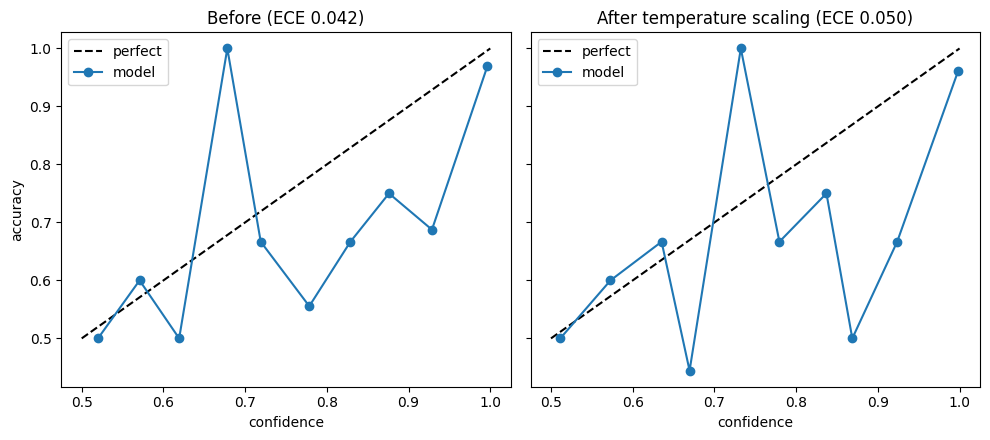

In [9]:
# calibration
def softmax(logits):
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def ece_and_bins(probs, labels, n_bins=10):
    """Expected calibration error: the average gap between how confident the model
    is and how often it is actually right."""
    confidence = probs.max(axis=1)
    correct = probs.argmax(axis=1) == labels
    edges = np.linspace(0.5, 1.0, n_bins + 1)
    ece, bin_conf, bin_acc = 0.0, [], []
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.sum() > 0:
            ece += in_bin.mean() * abs(correct[in_bin].mean() - confidence[in_bin].mean())
            bin_conf.append(confidence[in_bin].mean())
            bin_acc.append(correct[in_bin].mean())
    return ece, bin_conf, bin_acc


def find_temperature(logits, labels):
    """Try many temperatures T and pick the one that gives the lowest loss on the
    validation set. Dividing the logits by T makes probabilities more or less confident."""
    best_T, best_loss = 1.0, 1e9
    for T in np.arange(0.3, 5.0, 0.05):
        probs = softmax(logits / T)
        loss = -np.log(probs[np.arange(len(labels)), labels] + 1e-12).mean()
        if loss < best_loss:
            best_T, best_loss = T, loss
    return best_T


val_logits, val_y = get_logits(val_loader)
test_logits, test_y = get_logits(test_loader)

T = find_temperature(val_logits, val_y)
print("Temperature fitted on validation data:", round(T, 2))

probs_before = softmax(test_logits)
probs_after = softmax(test_logits / T)
ece_before, conf_b, acc_b = ece_and_bins(probs_before, test_y)
ece_after, conf_a, acc_a = ece_and_bins(probs_after, test_y)
print(f"ECE before: {ece_before:.3f}   ECE after temperature scaling: {ece_after:.3f}")
print("Test accuracy:", round((probs_before.argmax(1) == test_y).mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, title, conf, acc, ece in [(axes[0], "Before", conf_b, acc_b, ece_before),
                                  (axes[1], "After temperature scaling", conf_a, acc_a, ece_after)]:
    ax.plot([0.5, 1], [0.5, 1], "k--", label="perfect")
    ax.plot(conf, acc, "o-", label="model")
    ax.set_title(f"{title} (ECE {ece:.3f})")
    ax.set_xlabel("confidence")
    ax.legend()
axes[0].set_ylabel("accuracy")
plt.tight_layout()
plt.savefig("reliability_diagram.png", dpi=150)
plt.show()

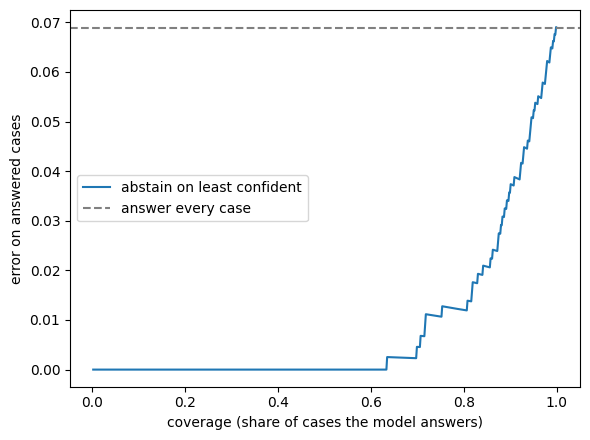

Answering every case: error 0.069
Answering the 90% most confident cases: error 0.036
Answering the 80% most confident cases: error 0.012
Answering the 70% most confident cases: error 0.005


In [10]:
# abstention (error versus coverage)
confidence = probs_after.max(axis=1)
correct = probs_after.argmax(axis=1) == test_y
order = np.argsort(-confidence)                     # most confident cases first
n_answered = np.arange(1, len(test_y) + 1)
error = 1 - np.cumsum(correct[order]) / n_answered
coverage = n_answered / len(test_y)

plt.figure(figsize=(6, 4.5))
plt.plot(coverage, error, label="abstain on least confident")
plt.axhline(error[-1], color="gray", linestyle="--", label="answer every case")
plt.xlabel("coverage (share of cases the model answers)")
plt.ylabel("error on answered cases")
plt.legend()
plt.tight_layout()
plt.savefig("risk_coverage.png", dpi=150)
plt.show()

print("Answering every case: error", round(error[-1], 3))
for share in [0.9, 0.8, 0.7]:
    print(f"Answering the {int(share * 100)}% most confident cases: error",
          round(error[int(share * len(test_y)) - 1], 3))

In [11]:
pred = probs_after.argmax(1)
tn, fp, fn, tp = confusion_matrix(test_y, pred).ravel()
print("Sensitivity (pneumonia found):", round(tp / (tp + fn), 3))
print("Specificity (normal found):", round(tn / (tn + fp), 3))
print("Images below 90% confidence:", (probs_after.max(1) < 0.9).sum(), "of", len(test_y))

Sensitivity (pneumonia found): 1.0
Specificity (normal found): 0.816
Images below 90% confidence: 38 of 624
